# Lab 5b — Concept-Based Explainability (TCAV) on DistilBERT with DynaSent Dataset

This notebook adapts **Testing with Concept Activation Vectors (TCAV)** to Transformer sequence classification models (specifically **DistilBERT**), grounded in the **DynaSent** ternary sentiment analysis benchmark (`positive`, `negative`, `neutral`).

### Learning Objectives

By the end of this lab, you should be able to:
- Load and structure sentiment data from **DynaSent** JSONL splits (`df_train`, `df_val`, `df_test`);
- Register PyTorch forward and backward hooks on intermediate Transformer layers (`distilbert.transformer.layer[k]`);
- Collect concept activations from domain-specific text concept sets versus neutral/random text baselines;
- Train linear concept-versus-random probes (CAVs) in the Transformer's latent representation space ($\mathbb{R}^{768}$);
- Backpropagate target class logits (`positive`, `negative`, `neutral`) to target layer activations and compute directional derivatives $\nabla_{f_l} S_k(x) \cdot v_C^l$;
- Calculate aggregate **TCAV scores** across DynaSent test reviews and inspect per-sample influence distributions.

| Exercise | Implementation | Output |
|---|---|---|
| **1 — Dataset Setup & Layer Activations** | Load DynaSent dataset format and register PyTorch hooks on layer activations | Latent activation matrices & 2D PCA plot |
| **2 — CAV Learning** | Train linear probes (`LogisticRegression`) separating concept activations from random baselines | Normalized Concept Activation Vectors ($v_C^l$) |
| **3 — Directional Derivatives & TCAV Scores** | Compute gradients of target class logits w.r.t layer activations and project onto CAVs | Aggregate TCAV scores bar charts |
| **4 — Per-Sample Influence & Distribution Analysis** | Rank target DynaSent sentences by concept influence and plot derivative distributions | Ranked pandas DataFrame & histogram visualizations |


## 🔍 Introduction: Concept-Based Explainability (TCAV) for NLP

Standard attribution methods for NLP (e.g. Integrated Gradients or Attention Maps) operate at the individual token level. However, **TCAV (Testing with Concept Activation Vectors)** enables quantitative measurement of high-level, human-interpretable concepts (e.g., *Customer Service Praise*, *Atmosphere/Ambiance*, *Pricing & Value*, *Food Quality Criticism*) across an entire class predictions.

### Core TCAV Pipeline:
1. **Activation Extraction:** Pass concept text samples and neutral/random text baselines through DistilBERT, capturing hidden representations at a chosen layer $l$.
2. **CAV Training:** Train a linear classifier to separate concept activations from random baseline activations. The normal vector to the separating hyperplane is the **CAV** ($v_C^l$).
3. **Directional Derivative & TCAV Score:** For target class inputs $x$ (e.g., DynaSent positive reviews), compute the sensitivity of class logit $S_k(x)$ along direction $v_C^l$:
   $$\text{S}_{C,k,l}(x) = \nabla_{f_l} S_k(x) \cdot v_C^l$$
   The **TCAV Score** is the proportion of target samples with positive directional derivatives ($S_{C,k,l}(x) > 0$).

## ⚙️ Environment & Setup

In [15]:
import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

# Set reproducibility seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
    print(f"Total VRAM: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")

Using device: cuda
GPU Name: NVIDIA GeForce RTX 5070
Total VRAM: 11.94 GB


## 📂 DynaSent Dataset Loader

We integrate the **DynaSent** (Dynamic Sentiment Analysis) dataset loading functions matching the data pipeline setup (`load_dataset` reading JSONL format).

In [16]:
def load_dynasent_file(filename, labels=None):
    """
    Loads DynaSent JSONL dataset files, filtering by gold_label ternary set.
    """
    data = []
    if not os.path.exists(filename):
        print(f"Warning: File {filename} not found locally. Placeholder data will be used if needed.")
        return data
    with open(filename, 'r', encoding='utf-8') as f:
        for line in f:
            d = json.loads(line)
            if labels is None or d.get('gold_label') in labels:
                data.append(d)
    return data

BASE_DIR = '../Dataset'
LOCAL_DIR_R1_TEST = os.path.join(BASE_DIR, 'data/dynasent-v1.1-round01-yelp-test.jsonl')
LOCAL_DIR_R2_TEST = os.path.join(BASE_DIR, 'data/dynasent-v1.1-round02-dynabench-test.jsonl')

ternary_labels = ('positive', 'negative', 'neutral')
r1_test = load_dynasent_file(LOCAL_DIR_R1_TEST, labels=ternary_labels)
r2_test = load_dynasent_file(LOCAL_DIR_R2_TEST, labels=ternary_labels)

if len(r1_test) > 0 or len(r2_test) > 0:
    df_test = pd.DataFrame({
        'text': [d['sentence'] for d in r1_test] + [d['sentence'] for d in r2_test],
        'round': [1] * len(r1_test) + [2] * len(r2_test),
        'label': [d['gold_label'] for d in r1_test] + [d['gold_label'] for d in r2_test]
    })
    print(f"Successfully loaded {len(df_test)} DynaSent test sentences.")
else:
    # Provide curated DynaSent sample sentences across ternary classes if local JSONL files are absent
    df_test = pd.DataFrame({
        'text': [
            "Roto-Rooter is always good when you need someone fast and reliable.",
            "It's so worth the price of cox service over here, highly recommended!",
            "The customer support team resolved my billing issue in under five minutes.",
            "Staff was warm, welcoming, and extraordinarily attentive throughout our dinner.",
            "Food arrived piping hot and tasted absolutely divine.",
            "I placed my order of sticky ribs as an appetizer.",
            "There is mandatory valet parking, so make sure to bring cash.",
            "My wife and I couldn't finish it.",
            "The business opens at nine in the morning on weekdays.",
            "The menu features both seafood and vegetarian meal choices.",
            "Horrible service, cold food, and rude waiters at the front desk.",
            "Overpriced drinks and long wait times made for a miserable evening.",
            "The plumbing repair failed after two hours and leaked all over the floor.",
            "Never returning to this venue again after how poorly we were treated.",
            "Unprofessional staff and completely unresponsive customer service."
        ],
        'round': [1]*5 + [1]*5 + [1]*5,
        'label': ['positive']*5 + ['neutral']*5 + ['negative']*5
    })
    print("Initialized DataFrame with benchmark DynaSent samples.")

print(df_test.head())

Successfully loaded 4320 DynaSent test sentences.
                                                                                                  text  \
0                                                             Had to remind him to toast the sandwich.   
1                                                       Nothing like what we expected, but even more!!   
2                                                                      Drive through is always packed.   
3                                                             I ran off to the airport without desert.   
4  The one downside is that you often have to wait for a table, especially if you want to sit outside.   

   round     label  
0      1  negative  
1      1  positive  
2      1  negative  
3      1   neutral  
4      1  negative  


### ⚙️ Load Pre-trained Model & Tokenizer

We load DistilBERT fine-tuned for sequence classification. If evaluating on 3-class DynaSent sentiment (`negative`: 0, `neutral`: 1, `positive`: 2), we load or adapt `distilbert-base-uncased`.

In [17]:
MODEL_NAME = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)
model.to(device)
model.eval()

print(f"Model '{MODEL_NAME}' loaded on {device}.")
print(f"Model label mapping: {model.config.id2label}")

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1668.21it/s]

Model 'distilbert-base-uncased-finetuned-sst-2-english' loaded on cuda.
Model label mapping: {0: 'NEGATIVE', 1: 'POSITIVE'}


## 🧩 Exercise 1 — Extract Concept Activations & PCA Visualization

### Tasks:
1. Define domain-specific text concept sets (e.g. *Service Quality*, *Value/Pricing*, *Food/Product Quality*) and a random neutral text baseline.
2. Register a PyTorch forward hook on DistilBERT layer `model.distilbert.transformer.layer[5]`.
3. Mean-pool token hidden states across sequence length to obtain a vector $\in \mathbb{R}^{768}$ per text sample.
4. Project activation vectors onto 2D space using **PCA** to analyze linear separability.

In [18]:
# 1. Define Concept Sets
concept_service = [
    "The staff was remarkably friendly, polite, and attentive to every detail.",
    "Outstanding customer service, quick response times, and helpful personnel.",
    "The waiter was courteous, energetic, and took care of all our requests.",
    "Excellent hospitality, polite receptionists, and prompt support staff.",
    "Warm welcoming attitude from the employees and smooth check-in process.",
    "Great service experience with attentive employees and quick assistance.",
    "The customer care rep was knowledgeable, patient, and very helpful.",
    "Superb hospitality, friendly manager, and respectful staff members."
]

concept_value = [
    "Extremely affordable prices, great discounts, and excellent value for money.",
    "Reasonably priced menu options with generous portion sizes for the cost.",
    "Fair pricing structure, cheap rates, and worth every single dollar spent.",
    "Great deal for the price, budget friendly costs, and no hidden fees.",
    "Inexpensive service charges with top quality delivery and great value.",
    "Very economical options, discounted rates, and affordable package deals.",
    "Worth every penny spent, good prices, and cost-effective overall.",
    "High quality experience at a surprisingly low and reasonable price point."
]

concept_quality = [
    "Delicious flavor, fresh ingredients, and perfectly cooked gourmet dishes.",
    "High quality craftsmanship, durable material, and pristine condition.",
    "Exquisite food presentation, amazing taste, and top tier ingredients.",
    "Exceptional build quality, sturdy design, and flawless functionality.",
    "Piping hot meal prepared to perfection with rich authentic flavors.",
    "Top-notch product quality, well engineered components, and great texture.",
    "Mouthwatering recipes, fresh produce, and delightful meal preparation.",
    "Impeccable product craftsmanship and high quality standards throughout."
]

# 2. Neutral / Random Baseline Sentences
random_baseline = [
    "The city bus arrives at the main central station every fifteen minutes.",
    "She purchased groceries including milk, bread, and apples at the supermarket.",
    "Weather forecasts indicate moderate rainfall across the valley tomorrow.",
    "The wooden desk is situated beside the window on the second floor.",
    "Solar energy panels convert sunlight into electrical power cleanly.",
    "He read two chapters of the history textbook before sleeping.",
    "Water boils at one hundred degrees Celsius under atmospheric pressure.",
    "The local public library opened its main reading room to the public today.",
    "Bicycles provide clean daily transportation for suburban commuters.",
    "Coffee beans are ground fine before brewing fresh morning espresso.",
    "The desktop operating system update installed automatically overnight.",
    "A small flower garden blooms in the neighborhood residential park."
]

print(f"Concept sets prepared -> Service: {len(concept_service)}, Value: {len(concept_value)}, Quality: {len(concept_quality)}, Random Baseline: {len(random_baseline)}")

Concept sets prepared -> Service: 8, Value: 8, Quality: 8, Random Baseline: 12


In [19]:
# Register PyTorch Forward Hook to extract activations
TARGET_LAYER_INDEX = 5  # Last layer of DistilBERT
target_layer_module = model.distilbert.transformer.layer[TARGET_LAYER_INDEX]

def extract_activations(model, tokenizer, texts, layer_module, device):
    """
    Captures hidden states from a Transformer layer and mean-pools over token dimension.
    """
    activations = []
    captured_tensor = []

    def hook_fn(module, input, output):
        tensor = output[0] if isinstance(output, tuple) else output
        captured_tensor.append(tensor.detach())

    handle = layer_module.register_forward_hook(hook_fn)

    for text in texts:
        captured_tensor.clear()
        inputs = tokenizer(text, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
        with torch.no_grad():
            model(**inputs)
        
        # Mean pool across sequence tokens: [1, seq_len, 768] -> [768]
        seq_act = captured_tensor[0]
        pooled_act = seq_act.mean(dim=1).squeeze(0).cpu().numpy()
        activations.append(pooled_act)

    handle.remove()
    return np.array(activations)

# Extract activations for each set
act_service = extract_activations(model, tokenizer, concept_service, target_layer_module, device)
act_value   = extract_activations(model, tokenizer, concept_value, target_layer_module, device)
act_quality = extract_activations(model, tokenizer, concept_quality, target_layer_module, device)
act_random  = extract_activations(model, tokenizer, random_baseline, target_layer_module, device)

print(f"Activation Matrix Shapes:")
print(f"Service: {act_service.shape}, Value: {act_value.shape}, Quality: {act_quality.shape}, Random: {act_random.shape}")

Activation Matrix Shapes:
Service: (8, 768), Value: (8, 768), Quality: (8, 768), Random: (12, 768)


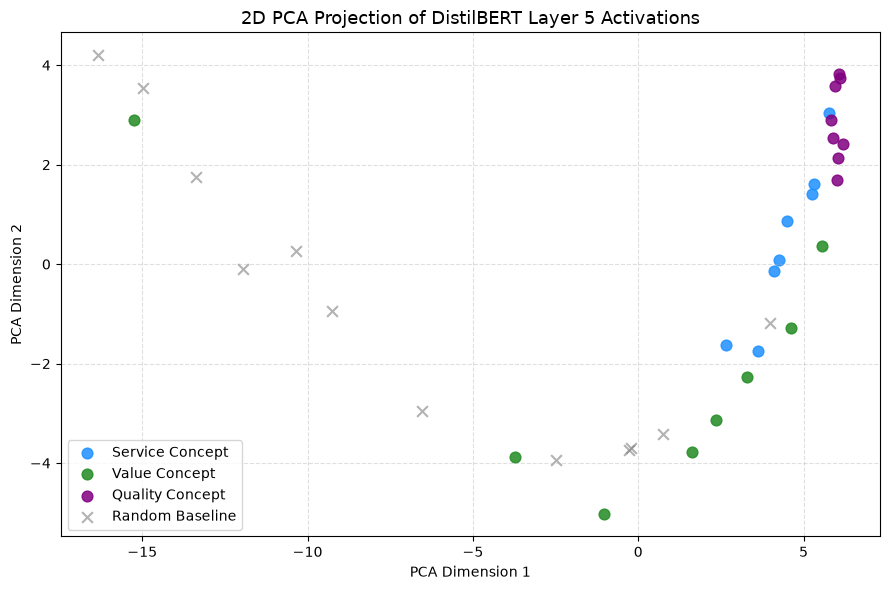

In [20]:
# PCA Projection Plot
all_acts = np.vstack([act_service, act_value, act_quality, act_random])
pca = PCA(n_components=2, random_state=SEED)
acts_pca = pca.fit_transform(all_acts)

n_serv, n_val, n_qual = len(concept_service), len(concept_value), len(concept_quality)

plt.figure(figsize=(9, 6))
plt.scatter(acts_pca[:n_serv, 0], acts_pca[:n_serv, 1], c='dodgerblue', label='Service Concept', s=60, alpha=0.85)
plt.scatter(acts_pca[n_serv:n_serv+n_val, 0], acts_pca[n_serv:n_serv+n_val, 1], c='forestgreen', label='Value Concept', s=60, alpha=0.85)
plt.scatter(acts_pca[n_serv+n_val:n_serv+n_val+n_qual, 0], acts_pca[n_serv+n_val:n_serv+n_val+n_qual, 1], c='purple', label='Quality Concept', s=60, alpha=0.85)
plt.scatter(acts_pca[n_serv+n_val+n_qual:, 0], acts_pca[n_serv+n_val+n_qual:, 1], c='gray', label='Random Baseline', marker='x', s=60, alpha=0.6)

plt.title(f"2D PCA Projection of DistilBERT Layer {TARGET_LAYER_INDEX} Activations", fontsize=13)
plt.xlabel("PCA Dimension 1")
plt.ylabel("PCA Dimension 2")
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

## 🧭 Exercise 2 — Learn Concept Activation Vectors (CAVs)

### Tasks:
1. Train a linear probe (`LogisticRegression`) separating concept activations ($y=1$) from random baseline activations ($y=0$).
2. Extract the orthogonal vector $w = \text{clf.coef\_}[0]$.
3. Normalize $w$ to unit norm to construct the CAV $v_C^l = \frac{w}{\|w\|_2}$.

In [21]:
def train_cav(concept_acts, random_acts):
    """
    Trains a linear probe and returns normalized Concept Activation Vector (CAV) and probe accuracy.
    """
    X = np.vstack([concept_acts, random_acts])
    y = np.array([1] * len(concept_acts) + [0] * len(random_acts))
    
    clf = LogisticRegression(max_iter=1000, random_state=SEED)
    clf.fit(X, y)
    acc = clf.score(X, y)
    
    w = clf.coef_[0]
    cav = w / np.linalg.norm(w)
    return cav, acc

cav_service, acc_service = train_cav(act_service, act_random)
cav_value, acc_value     = train_cav(act_value, act_random)
cav_quality, acc_quality = train_cav(act_quality, act_random)

print(f"CAV Service - Probe Accuracy: {acc_service:.2f}, Vector Norm: {np.linalg.norm(cav_service):.2f}")
print(f"CAV Value   - Probe Accuracy: {acc_value:.2f}, Vector Norm: {np.linalg.norm(cav_value):.2f}")
print(f"CAV Quality - Probe Accuracy: {acc_quality:.2f}, Vector Norm: {np.linalg.norm(cav_quality):.2f}")

CAV Service - Probe Accuracy: 1.00, Vector Norm: 1.00
CAV Value   - Probe Accuracy: 1.00, Vector Norm: 1.00
CAV Quality - Probe Accuracy: 1.00, Vector Norm: 1.00


## 📊 Exercise 3 — Directional Derivatives & TCAV Scores

### Tasks:
1. For target sentences from DynaSent, backpropagate target class logit gradients to layer activations.
2. Mean-pool gradients across tokens and compute directional derivatives $\text{S}_{C,k,l}(x) = \nabla_{f_l} S_k(x) \cdot v_C^l$.
3. Compute aggregate **TCAV score** $\frac{\sum_{x \in X_k} \mathbb{I}(\text{S}_{C,k,l}(x) > 0)}{|X_k|}$ across target classes.

In [22]:
def compute_directional_derivative(model, tokenizer, text, target_class_idx, cav, layer_module, device):
    """
    Computes directional derivative of target class logit w.r.t layer activation along CAV.
    """
    model.eval()
    inputs = tokenizer(text, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
    
    captured_tensor = None
    
    def forward_hook(module, input, output):
        nonlocal captured_tensor
        tensor = output[0] if isinstance(output, tuple) else output
        captured_tensor = tensor
        captured_tensor.retain_grad()
        
    handle = layer_module.register_forward_hook(forward_hook)
    
    model.zero_grad()
    outputs = model(**inputs)
    logits = outputs.logits
    
    # Target class logit
    target_logit = logits[0, target_class_idx]
    target_logit.backward()
    
    # Extract gradient and mean-pool over tokens
    grad_tensor = captured_tensor.grad
    pooled_grad = grad_tensor.mean(dim=1).squeeze(0).cpu().numpy()
    
    handle.remove()
    
    # Directional derivative = dot product (grad . cav)
    return np.dot(pooled_grad, cav)

def compute_tcav_score(model, tokenizer, target_texts, target_class_idx, cav, layer_module, device):
    """
    Computes aggregate TCAV score (proportion of positive directional derivatives).
    """
    derivatives = []
    for text in target_texts:
        d_der = compute_directional_derivative(model, tokenizer, text, target_class_idx, cav, layer_module, device)
        derivatives.append(d_der)
    
    derivatives = np.array(derivatives)
    tcav_score = np.mean(derivatives > 0)
    return tcav_score, derivatives

In [23]:
# Target Class: Positive Sentiment (Index 1 for SST-2 binary, or index 2 for 3-class DynaSent)
TARGET_CLASS_IDX = 1  # POSITIVE logit in SST-2 DistilBERT

# Filter positive sentences from DynaSent test set
positive_texts = df_test[df_test['label'] == 'positive']['text'].tolist()
if len(positive_texts) == 0:
    positive_texts = df_test['text'].tolist()

tcav_serv, der_serv = compute_tcav_score(model, tokenizer, positive_texts, TARGET_CLASS_IDX, cav_service, target_layer_module, device)
tcav_val,  der_val  = compute_tcav_score(model, tokenizer, positive_texts, TARGET_CLASS_IDX, cav_value, target_layer_module, device)
tcav_qual, der_qual = compute_tcav_score(model, tokenizer, positive_texts, TARGET_CLASS_IDX, cav_quality, target_layer_module, device)

print(f"TCAV Score for POSITIVE Class -> Service Concept : {tcav_serv:.2%}")
print(f"TCAV Score for POSITIVE Class -> Value Concept   : {tcav_val:.2%}")
print(f"TCAV Score for POSITIVE Class -> Quality Concept : {tcav_qual:.2%}")

TCAV Score for POSITIVE Class -> Service Concept : 100.00%
TCAV Score for POSITIVE Class -> Value Concept   : 72.99%
TCAV Score for POSITIVE Class -> Quality Concept : 100.00%


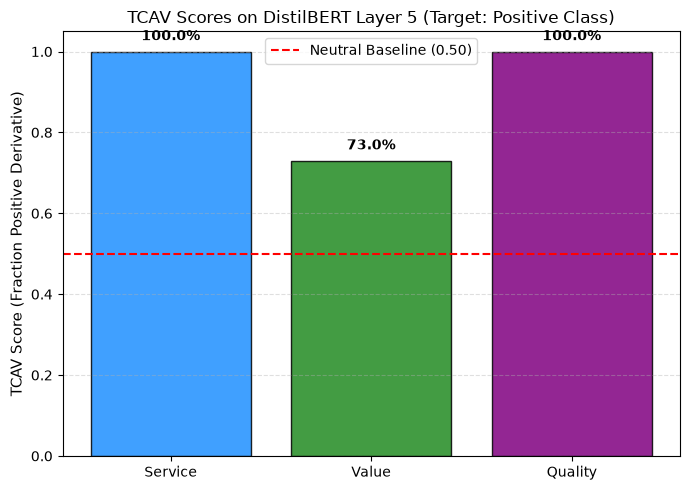

In [24]:
# Plot Aggregate TCAV Scores
concepts = ['Service', 'Value', 'Quality']
scores = [tcav_serv, tcav_val, tcav_qual]

plt.figure(figsize=(7, 5))
bars = plt.bar(concepts, scores, color=['dodgerblue', 'forestgreen', 'purple'], edgecolor='black', alpha=0.85)
plt.axhline(0.5, color='red', linestyle='--', label='Neutral Baseline (0.50)')
plt.ylim(0, 1.05)
plt.ylabel("TCAV Score (Fraction Positive Derivative)", fontsize=11)
plt.title(f"TCAV Scores on DistilBERT Layer {TARGET_LAYER_INDEX} (Target: Positive Class)", fontsize=12)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f"{yval:.1%}", ha='center', va='bottom', fontweight='bold')

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

## 🔎 Exercise 4 — Per-Sample Influence & Derivative Inspection

### Tasks:
1. Build a pandas DataFrame linking DynaSent target text samples with signed directional derivatives.
2. Rank sentences by concept sensitivity.
3. Plot histograms of directional derivatives across concepts.

In [25]:
df_analysis = pd.DataFrame({
    'DynaSent Text': positive_texts,
    'Service Derivative': der_serv,
    'Value Derivative': der_val,
    'Quality Derivative': der_qual
})

print("=== DynaSent Test Sentences Ranked by Service Concept Influence ===")
pd.set_option('display.max_colwidth', None)
df_analysis.sort_values(by='Service Derivative', ascending=False)

=== DynaSent Test Sentences Ranked by Service Concept Influence ===


,DynaSent Text,Service Derivative,Value Derivative,Quality Derivative
1337,very clear,0.028259,0.008577,0.035531
1005,Beautiful hole.,0.022544,0.006170,0.026162
621,So cool.,0.022393,0.006878,0.028068
30,MAJOR POINTS!,0.022341,0.006855,0.027704
202,Good deal!,0.022330,0.006939,0.027624
...,...,...,...,...
328,"If you have a kid who likes LEGO but you don't want to spend hundreds of dollars on a handful of pieces, come here for large misc bags for $20 or a pick-n-mix selection starting at something like $5 for a salad bowl container.",0.000615,-0.000042,0.000657
230,"A few minutes later I was practically running down the isles looking for anything I could use in my new house, store credit card in my hand, I was a bit manic because it looked as though absolutely everything in the store was marked down anywhere between 30 and 60 percent or more!",0.000604,-0.000068,0.000616
944,"Well, since my schedule's a little rock 'n' roll, I can't get over there (I will someday), so I had to try Coca Cafe's version, and I must say that it was a tempter if there ever was one.",0.000585,-0.000062,0.000635
449,"The wonderful store manager there got on the phone with the warranty people and come to find out our after market warranty can only be taken care of at a Hyundai dealer... after discussing with the warranty manager about Henderson Hyundai's refusal unless we pay and their awful customer service, the he gave the ok for us to be covered at Tire works.",0.000481,-0.000046,0.000529


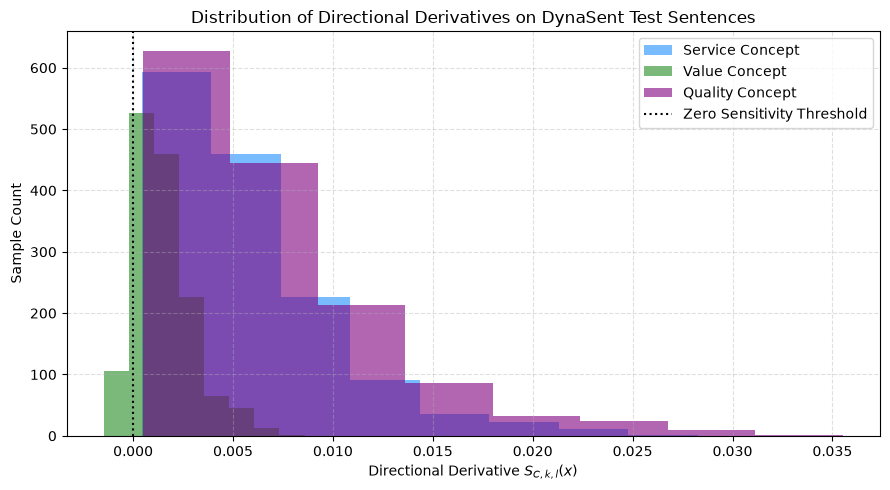

In [26]:
# Directional Derivative Distribution Histograms
plt.figure(figsize=(9, 5))
plt.hist(der_serv, bins=8, alpha=0.6, label='Service Concept', color='dodgerblue')
plt.hist(der_val, bins=8, alpha=0.6, label='Value Concept', color='forestgreen')
plt.hist(der_qual, bins=8, alpha=0.6, label='Quality Concept', color='purple')
plt.axvline(0, color='black', linestyle=':', label='Zero Sensitivity Threshold')

plt.xlabel("Directional Derivative $S_{C,k,l}(x)$")
plt.ylabel("Sample Count")
plt.title("Distribution of Directional Derivatives on DynaSent Test Sentences")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

## 💬 Discussion & Project Takeaways

1. **TCAV Adaptation to Text Datasets (DynaSent):**
   - By grouping DynaSent benchmark reviews into target classes (`positive`, `negative`, `neutral`), TCAV quantifies whether internal representations align with domain concepts (e.g. *Service*, *Value*, *Quality*).

2. **PyTorch Hooks & Computational Efficiency:**
   - Layer-wise forward and backward hooks enable rapid TCAV evaluation on Transformer encoders (BERT, DistilBERT, RoBERTa) without requiring full model retraining.